# Inspection Industrielle de PCB : Détection de Défauts (YOLO11) et Aide à la Décision Floue

Système d'inspection optique automatisée (AOI) pour circuits imprimés basé sur le dataset industriel **PCB-IND v4** :
- **Détection d'objets** : Fine-tuning accéléré de **YOLO11m** (`batch=8`, optimisation RTX 5060) pour détecter et localiser 8 types de défauts de surface.
- **Optimisation opérationnelle** : Réglage fin du seuil de confiance sur le jeu de validation pour maximiser le F1-score.
- **Logique Floue (Mamdani)** : Système expert évaluant le niveau de risque global (gravité, nombre d'occurrences, confiance) pour statuer sur la conformité du PCB (*Accepter*, *Réparer/Inspecter*, *Rejeter*).

### Classes de défauts (PCB-IND v4)

| ID | Classe | Description |
|---:|---|---|
| 0 | `mouse_bite` | Entaille sur piste conductrice |
| 1 | `missing_copper` | Manque de cuivre |
| 2 | `scratch` | Rayure de surface |
| 3 | `spurious_copper` | Cuivre parasite |
| 4 | `copper_burr` | Bavure de cuivre |
| 5 | `stain` | Tache superficielle |
| 6 | `short` | Court-circuit |
| 7 | `open` | Circuit ouvert |

## 1. Installation des dépendances et imports

In [1]:
import sys
import subprocess

# Installation des dépendances requises
packages = [
    "ultralytics==8.4.211",
    "scikit-fuzzy==0.5.0",
    "seaborn>=0.13.0",
    "pandas>=2.0.0",
    "matplotlib>=3.7.0",
    "jinja2>=3.1.2",
]
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])
print("Installation terminée.")

Installation terminée.


In [2]:
import os
import cv2
import json
import time
import random
import shutil
import zipfile
import hashlib
import warnings
import urllib.request
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown

import torch
from packaging.version import Version
import ultralytics
from ultralytics import YOLO
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# Configuration générale et reproductibilité
warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Ultralytics :", ultralytics.__version__)
print("NumPy       :", np.__version__)
print("PyTorch     :", torch.__version__)
print("Dispositif  :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Ultralytics : 8.4.211
NumPy       : 2.5.4
PyTorch     : 2.14.1+cu130
Dispositif  : NVIDIA GeForce RTX 5060 Laptop GPU


## 2. Configuration expérimentale

In [3]:
# Profil d'entraînement ("SMOKE", "STANDARD", "QUALITY")
PROFILE = "QUALITY"
PROFILES = {
    "SMOKE": dict(model="yolo11n.pt", epochs=2, patience=2, batch=8,
                  run_name="pcb_ind_smoke", cache=False),
    "STANDARD": dict(model="yolo11s.pt", epochs=100, patience=25, batch=-1,
                     run_name="pcb_ind_yolo11s", cache="disk"),
    "QUALITY": dict(model="yolo11m.pt", epochs=80, patience=20, batch=8,
                    run_name="pcb_ind_yolo11m_b8", cache="disk"),
}
assert PROFILE in PROFILES

BASE = Path("/content") if Path("/content").exists() else Path.cwd()
WORK = BASE / "pcb_ind_project"
RAW = WORK / "raw"
RUNS = WORK / "runs"
EXPORTS = WORK / "exports"
for d in [WORK, RAW, RUNS, EXPORTS]:
    d.mkdir(parents=True, exist_ok=True)

CONFIG = {
    **PROFILES[PROFILE],
    "imgsz": 640,
    "optimizer": "AdamW",
    "lr0": 0.001,
    "lrf": 0.01,
    "weight_decay": 0.0005,
    "warmup_epochs": 3.0,
    "cos_lr": True,
    "close_mosaic": 15,
    "hsv_h": 0.015,
    "hsv_s": 0.30,
    "hsv_v": 0.20,
    "degrees": 15.0,
    "translate": 0.03,
    "scale": 0.15,
    "shear": 0.0,
    "perspective": 0.0,
    "flipud": 0.5,
    "fliplr": 0.5,
    "mosaic": 0.50,
    "mixup": 0.0,
    "copy_paste": 0.15,
    "erasing": 0.0,
    "multi_scale": False,
    "amp": True,
    "seed": SEED,
    "deterministic": True,
    "workers": 4,
}

def select_safe_device():
    if torch.cuda.is_available():
        try:
            t = torch.zeros(1, device="cuda")
            del t
            return 0
        except Exception:
            return "cpu"
    return "cpu"

DEVICE = select_safe_device()
pd.Series(CONFIG, name="valeur").to_frame()

,valeur
model,yolo11m.pt
epochs,80
patience,20
batch,8
run_name,pcb_ind_yolo11m_b8
cache,disk
imgsz,640
optimizer,AdamW
lr0,0.001
lrf,0.01


## 3. Téléchargement et préparation du dataset PCB-IND v4

In [4]:
# Téléchargement et vérification de l'archive officielle PCB-IND v4
DATA_URL = "https://zenodo.org/records/19723114/files/PCB-IND_v4.zip?download=1"
EXPECTED_MD5 = "1325f8dffeb73bef4db34fbd22b31ec5"
ZIP_PATH = RAW / "PCB-IND_v4.zip"

if not ZIP_PATH.exists():
    print("Téléchargement de PCB-IND v4 (~101 Mo)...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)

md5 = hashlib.md5(ZIP_PATH.read_bytes()).hexdigest()
assert md5 == EXPECTED_MD5, "Erreur d'intégrité de l'archive MD5."
print("MD5 vérifié :", md5)

DATA_ROOT = RAW / "PCB-IND_v4"
if not (DATA_ROOT / "classes.json").exists():
    DATA_ROOT.mkdir(exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as zf:
        for member in zf.infolist():
            target = (DATA_ROOT / member.filename).resolve()
            assert str(target).startswith(str(DATA_ROOT.resolve())), member.filename
        zf.extractall(DATA_ROOT)

YOLO_ROOT = DATA_ROOT / "YOLO"
CLASSES_META = json.loads((DATA_ROOT / "classes.json").read_text())
CLASSES = [c["name"] for c in sorted(CLASSES_META["classes"], key=lambda x: x["id"])]
print("Classes officielles :", CLASSES)

MD5 vérifié : 1325f8dffeb73bef4db34fbd22b31ec5
Classes officielles : ['mouse_bite', 'missing_copper', 'scratch', 'spurious_copper', 'copper_burr', 'stain', 'short', 'open']


In [5]:
# Audit des images, nettoyage des boîtes nulles et création de data.yaml
EXPECTED_COUNTS = {"train": 3833, "val": 478, "test": 478}
records = {}
all_annotation_rows = []
rejected_annotations = []
raw_annotation_count = 0

for split, expected in EXPECTED_COUNTS.items():
    image_dir = YOLO_ROOT / "images" / split
    label_dir = YOLO_ROOT / "labels" / split
    images = sorted(image_dir.glob("*.jpg"))
    labels = sorted(label_dir.glob("*.txt"))
    assert len(images) == expected, (split, len(images))
    assert len(labels) == expected, (split, len(labels))

    split_records = []
    for image_path in images:
        label_path = label_dir / f"{image_path.stem}.txt"
        assert label_path.exists(), label_path
        with Image.open(image_path) as im:
            width, height = im.size
            assert (width, height) == (300, 300), (image_path, im.size)

        original_text = label_path.read_text()
        boxes = []
        cleaned_lines = []
        for line_number, line in enumerate(original_text.splitlines(), 1):
            if not line.strip():
                continue
            raw_annotation_count += 1
            values = line.split()
            assert len(values) == 5, (label_path, line_number)
            cid = int(values[0])
            xc, yc, bw, bh = map(float, values[1:])
            assert 0 <= cid < len(CLASSES), (label_path, line_number, cid)

            # Ignorer les annotations avec dimension nulle
            if bw <= 0 or bh <= 0:
                rejected_annotations.append({
                    "split": split, "fichier": str(label_path.relative_to(DATA_ROOT)),
                    "ligne": line_number, "annotation": line, "motif": "aire nulle",
                })
                continue

            xc = float(np.clip(xc, 0.0, 1.0))
            yc = float(np.clip(yc, 0.0, 1.0))
            bw = float(np.clip(bw, np.finfo(float).eps, 1.0))
            bh = float(np.clip(bh, np.finfo(float).eps, 1.0))
            cleaned_line = f"{cid} {xc:.8f} {yc:.8f} {bw:.8f} {bh:.8f}"
            cleaned_lines.append(cleaned_line)
            boxes.append((cid, xc, yc, bw, bh))
            all_annotation_rows.append({
                "split": split, "image_id": image_path.stem, "classe": CLASSES[cid],
                "cid": cid, "aire_relative_pct": 100*bw*bh,
                "largeur_px": bw*width, "hauteur_px": bh*height,
            })

        cleaned_text = "\n".join(cleaned_lines) + ("\n" if cleaned_lines else "")
        if cleaned_text != original_text:
            label_path.write_text(cleaned_text)

        split_records.append({"image": image_path, "label": label_path,
                              "image_id": image_path.stem, "boxes": boxes})
    records[split] = split_records
    print(f"{split:5s}: {len(images)} images | négatives={sum(not r['boxes'] for r in split_records)} | boîtes valides={sum(len(r['boxes']) for r in split_records)}")

boxes_df = pd.DataFrame(all_annotation_rows)
cleaning_report_path = EXPORTS / "annotations_ecartees.json"
cleaning_report_path.write_text(json.dumps(rejected_annotations, indent=2, ensure_ascii=False))

# Définition du fichier data.yaml pour YOLO
DATA_YAML = WORK / "data.yaml"
data_yaml_content = f"path: {YOLO_ROOT}\ntrain: images/train\nval: images/val\ntest: images/test\nnames: {CLASSES}\n"
DATA_YAML.write_text(data_yaml_content)
print("Fichier data.yaml configuré.")

train: 3833 images | négatives=115 | boîtes valides=4746
val  : 478 images | négatives=3 | boîtes valides=638
test : 478 images | négatives=9 | boîtes valides=547
Fichier data.yaml configuré.


## 4. Analyse exploratoire des données (EDA)

,split,images,negatives,boites,missing_copper,copper_burr,mouse_bite,spurious_copper,stain,scratch,short,open
0,train,3833,115,4746,1364,1023,654,576,493,280,255,101
1,val,478,3,638,218,75,99,41,39,91,58,17
2,test,478,9,547,132,76,91,43,52,92,47,14


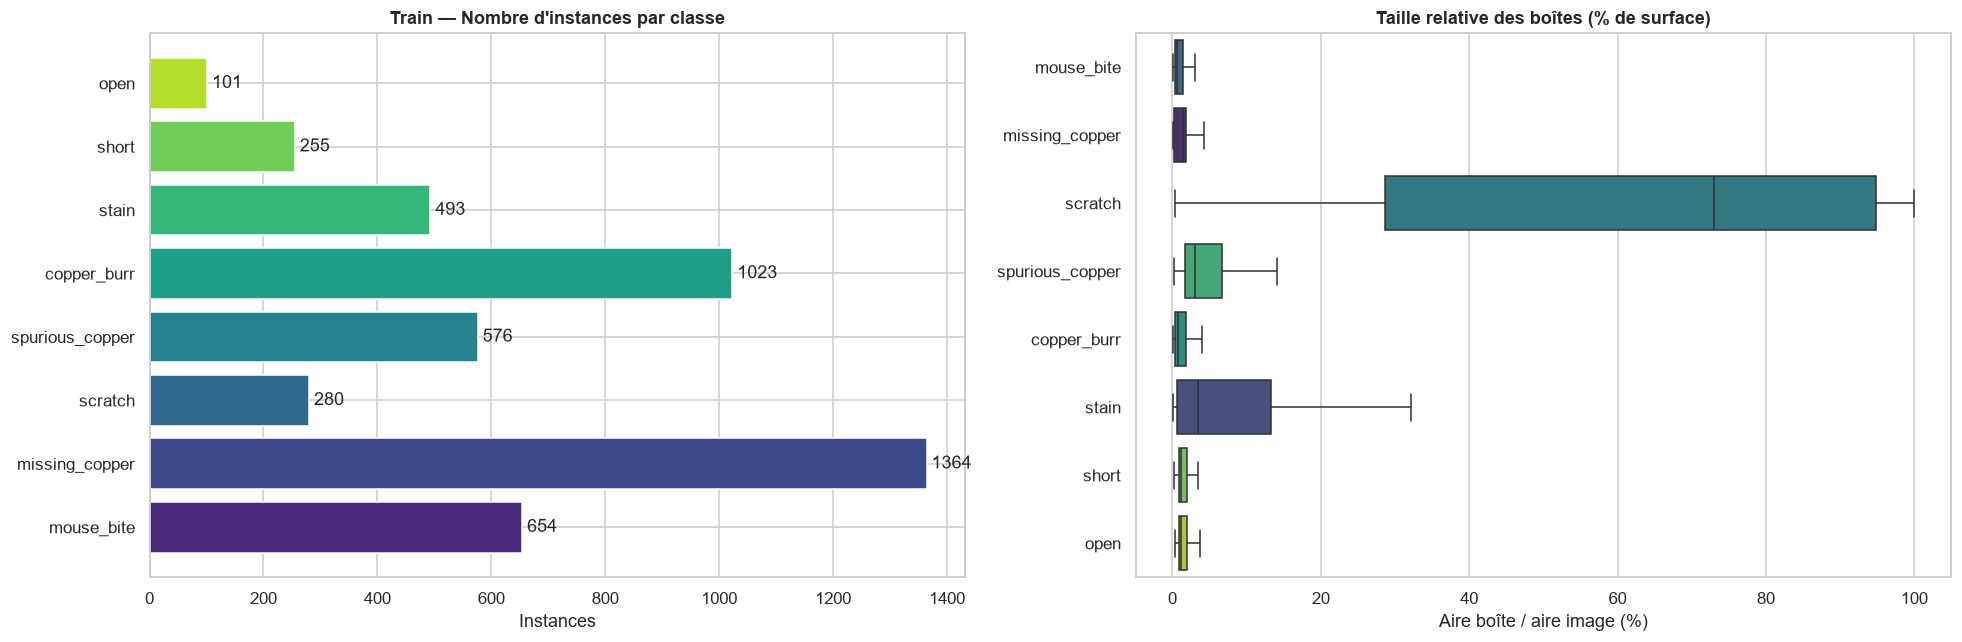

In [6]:
# Distribution des classes et dimensions relatives des défauts
summary = []
for split in EXPECTED_COUNTS:
    split_boxes = boxes_df[boxes_df.split == split]
    row = {"split": split, "images": len(records[split]),
           "negatives": sum(not r["boxes"] for r in records[split]),
           "boites": len(split_boxes)}
    row.update(split_boxes["classe"].value_counts().to_dict())
    summary.append(row)
summary = pd.DataFrame(summary).fillna(0)
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
train_counts = boxes_df[boxes_df.split == "train"]["classe"].value_counts().reindex(CLASSES, fill_value=0)
axes[0].barh(train_counts.index, train_counts.values, color=sns.color_palette("viridis", 8))
axes[0].set_title("Train — Nombre d'instances par classe")
axes[0].set_xlabel("Instances")
for i, value in enumerate(train_counts.values):
    axes[0].text(value, i, f" {value}", va="center")

sns.boxplot(data=boxes_df, x="aire_relative_pct", y="classe", order=CLASSES,
            hue="classe", palette="viridis", legend=False, showfliers=False, ax=axes[1])
axes[1].set_title("Taille relative des boîtes (% de surface)")
axes[1].set_xlabel("Aire boîte / aire image (%)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

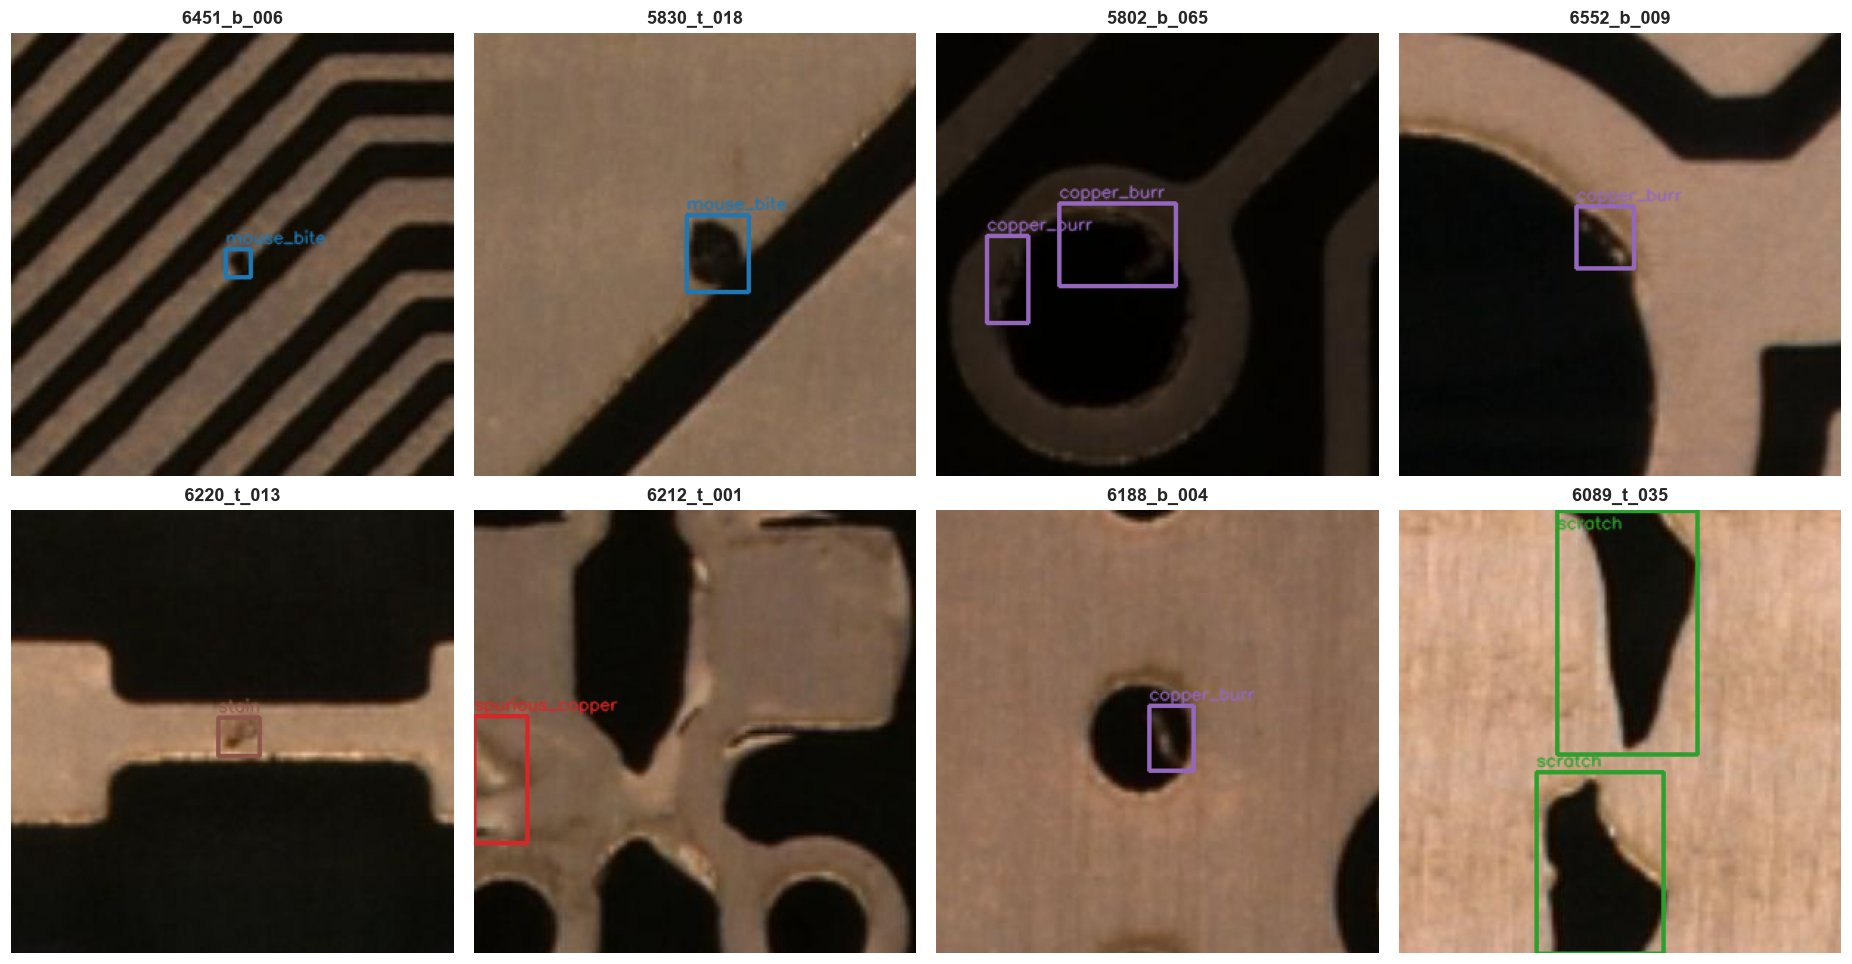

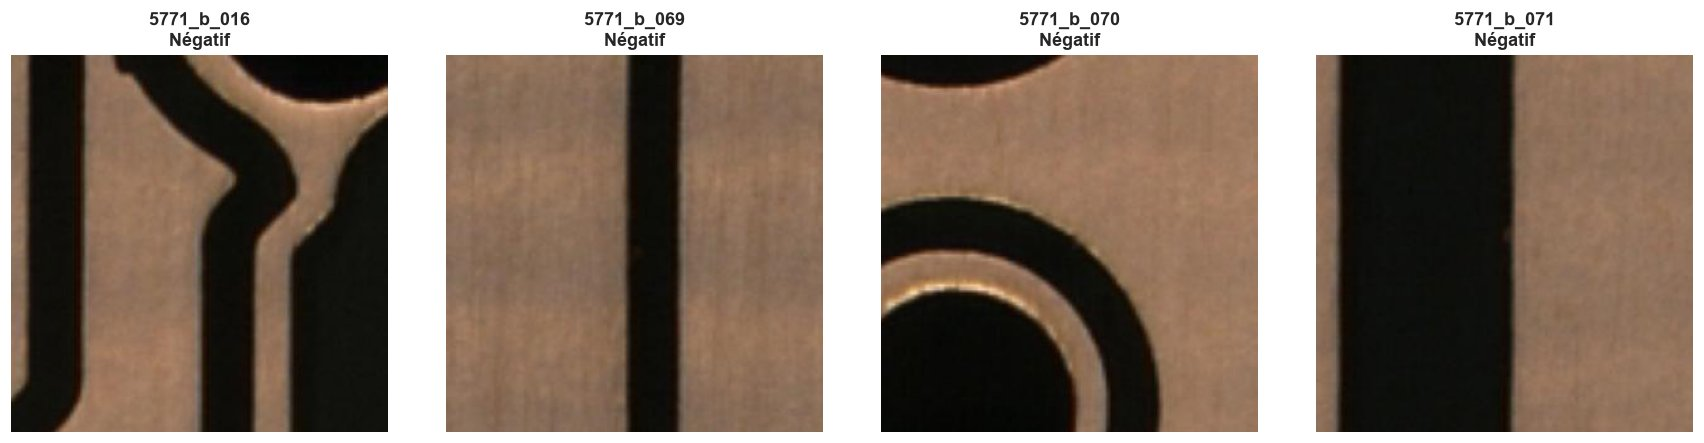

In [7]:
# Visualisation d'échantillons avec boîtes englobantes et images négatives
CLASS_COLORS = dict(zip(CLASSES, sns.color_palette("tab10", len(CLASSES)).as_hex()))

def yolo_to_xyxy(box, width=300, height=300):
    cid, xc, yc, bw, bh = box
    return (int((xc-bw/2)*width), int((yc-bh/2)*height),
            int((xc+bw/2)*width), int((yc+bh/2)*height), cid)

def draw_ground_truth(record, ax, title=None):
    image = np.array(Image.open(record["image"]).convert("RGB"))
    for box in record["boxes"]:
        x1, y1, x2, y2, cid = yolo_to_xyxy(box)
        color_hex = CLASS_COLORS[CLASSES[cid]].lstrip("#")
        color = tuple(int(color_hex[i:i+2], 16) for i in (0, 2, 4))
        cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)
        cv2.putText(image, CLASSES[cid], (x1, max(12, y1-4)), cv2.FONT_HERSHEY_SIMPLEX, 0.38, color, 1, cv2.LINE_AA)
    ax.imshow(image)
    ax.axis("off")
    ax.set_title(title or record["image_id"])
    return image

# Échantillons annotés
samples = random.Random(SEED).sample([r for r in records["train"] if r["boxes"]], 8)
fig, axes = plt.subplots(2, 4, figsize=(17, 9))
for r, ax in zip(samples, axes.flat):
    draw_ground_truth(r, ax)
plt.tight_layout()
plt.show()

# Échantillons sans défaut (négatifs)
negative_samples = [r for r in records["train"] if not r["boxes"]][:4]
fig, axes = plt.subplots(1, len(negative_samples), figsize=(16, 4))
for r, ax in zip(negative_samples, axes):
    ax.imshow(Image.open(r["image"]))
    ax.axis("off")
    ax.set_title(r["image_id"] + "\nNégatif")
plt.tight_layout()
plt.show()

## 5. Entraînement du modèle YOLO11m

In [8]:
# Entraînement / Fine-tuning de YOLO11m
RUN_DIR = RUNS / CONFIG["run_name"]
LAST_WEIGHTS = RUN_DIR / "weights" / "last.pt"

if LAST_WEIGHTS.exists():
    print(f"Reprise de l'entraînement : {LAST_WEIGHTS}")
    model = YOLO(str(LAST_WEIGHTS))
    train_results = model.train(resume=True)
else:
    print(f"Démarrage de l'entraînement : {CONFIG['model']}")
    model = YOLO(CONFIG["model"])
    train_results = model.train(
        data=str(DATA_YAML), epochs=CONFIG["epochs"], patience=CONFIG["patience"],
        batch=CONFIG["batch"], imgsz=CONFIG["imgsz"], device=DEVICE,
        optimizer=CONFIG["optimizer"], lr0=CONFIG["lr0"], lrf=CONFIG["lrf"],
        weight_decay=CONFIG["weight_decay"], warmup_epochs=CONFIG["warmup_epochs"],
        cos_lr=CONFIG["cos_lr"], close_mosaic=CONFIG["close_mosaic"],
        hsv_h=CONFIG["hsv_h"], hsv_s=CONFIG["hsv_s"], hsv_v=CONFIG["hsv_v"],
        degrees=CONFIG["degrees"], translate=CONFIG["translate"], scale=CONFIG["scale"],
        shear=CONFIG["shear"], perspective=CONFIG["perspective"],
        flipud=CONFIG["flipud"], fliplr=CONFIG["fliplr"], mosaic=CONFIG["mosaic"],
        mixup=CONFIG["mixup"], erasing=CONFIG["erasing"], multi_scale=CONFIG["multi_scale"],
        amp=CONFIG["amp"], cache=CONFIG["cache"], seed=CONFIG["seed"],
        deterministic=CONFIG["deterministic"], workers=CONFIG["workers"],
        project=str(RUNS), name=CONFIG["run_name"], exist_ok=True,
        save=True, plots=True, verbose=True,
    )

BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
print("Meilleur checkpoint sauvegardé :", BEST_WEIGHTS)

Reprise de l'entraînement : c:\Users\firas\OneDrive\Desktop\Projet Douik\pcb_ind_project\runs\pcb_ind_yolo11m_b8\weights\last.pt
New https://pypi.org/project/ultralytics/8.4.216 available  Update with 'pip install -U ultralytics'
WARNING model 'c:\Users\firas\OneDrive\Desktop\Projet Douik\pcb_ind_project\runs\pcb_ind_yolo11m_b8\weights\last.pt' is not a resumable training checkpoint (missing epoch/optimizer state). Use 'resume' only to continue incomplete training. Starting new training instead.
Ultralytics 8.4.211  Python-3.12.10 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8151MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1

## 6. Analyse des courbes d’apprentissage

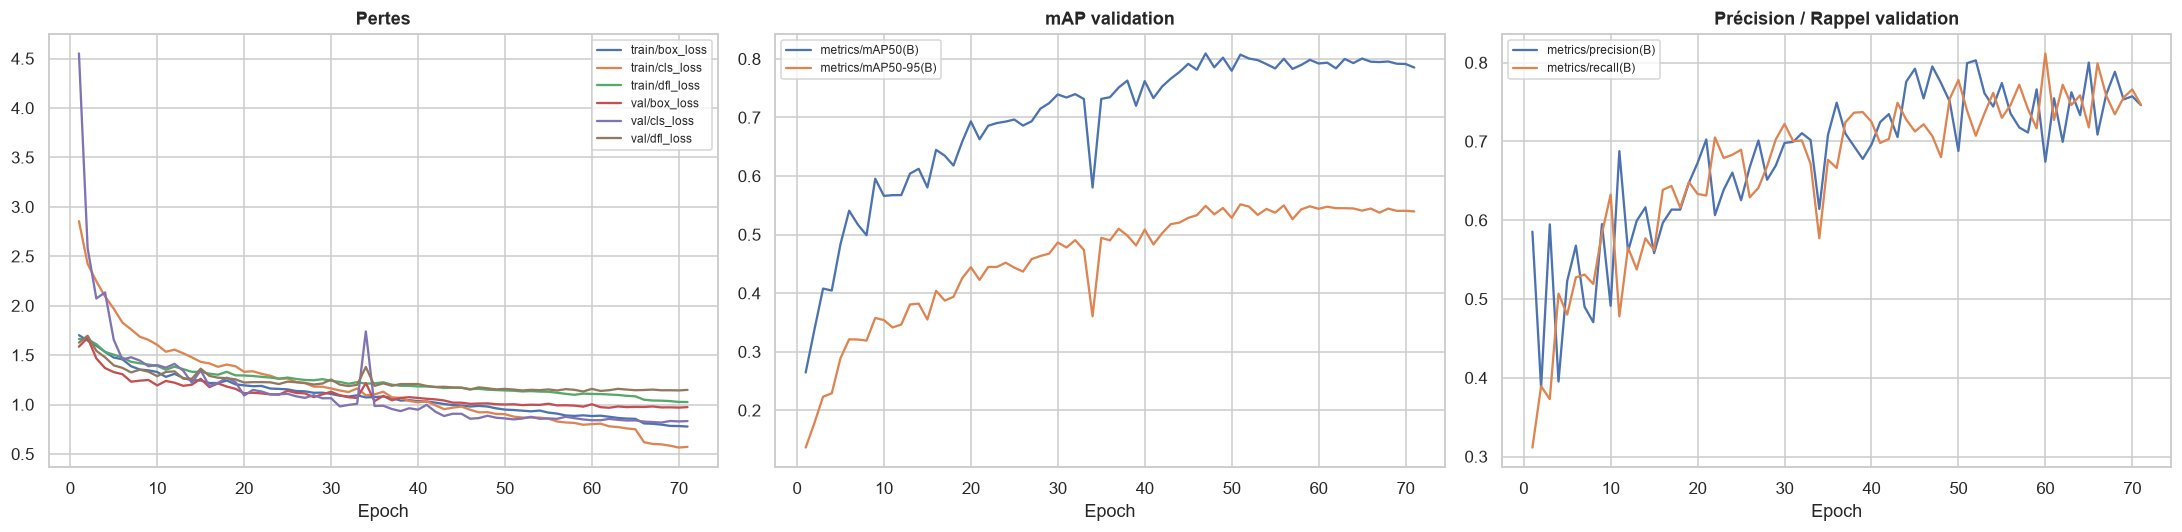

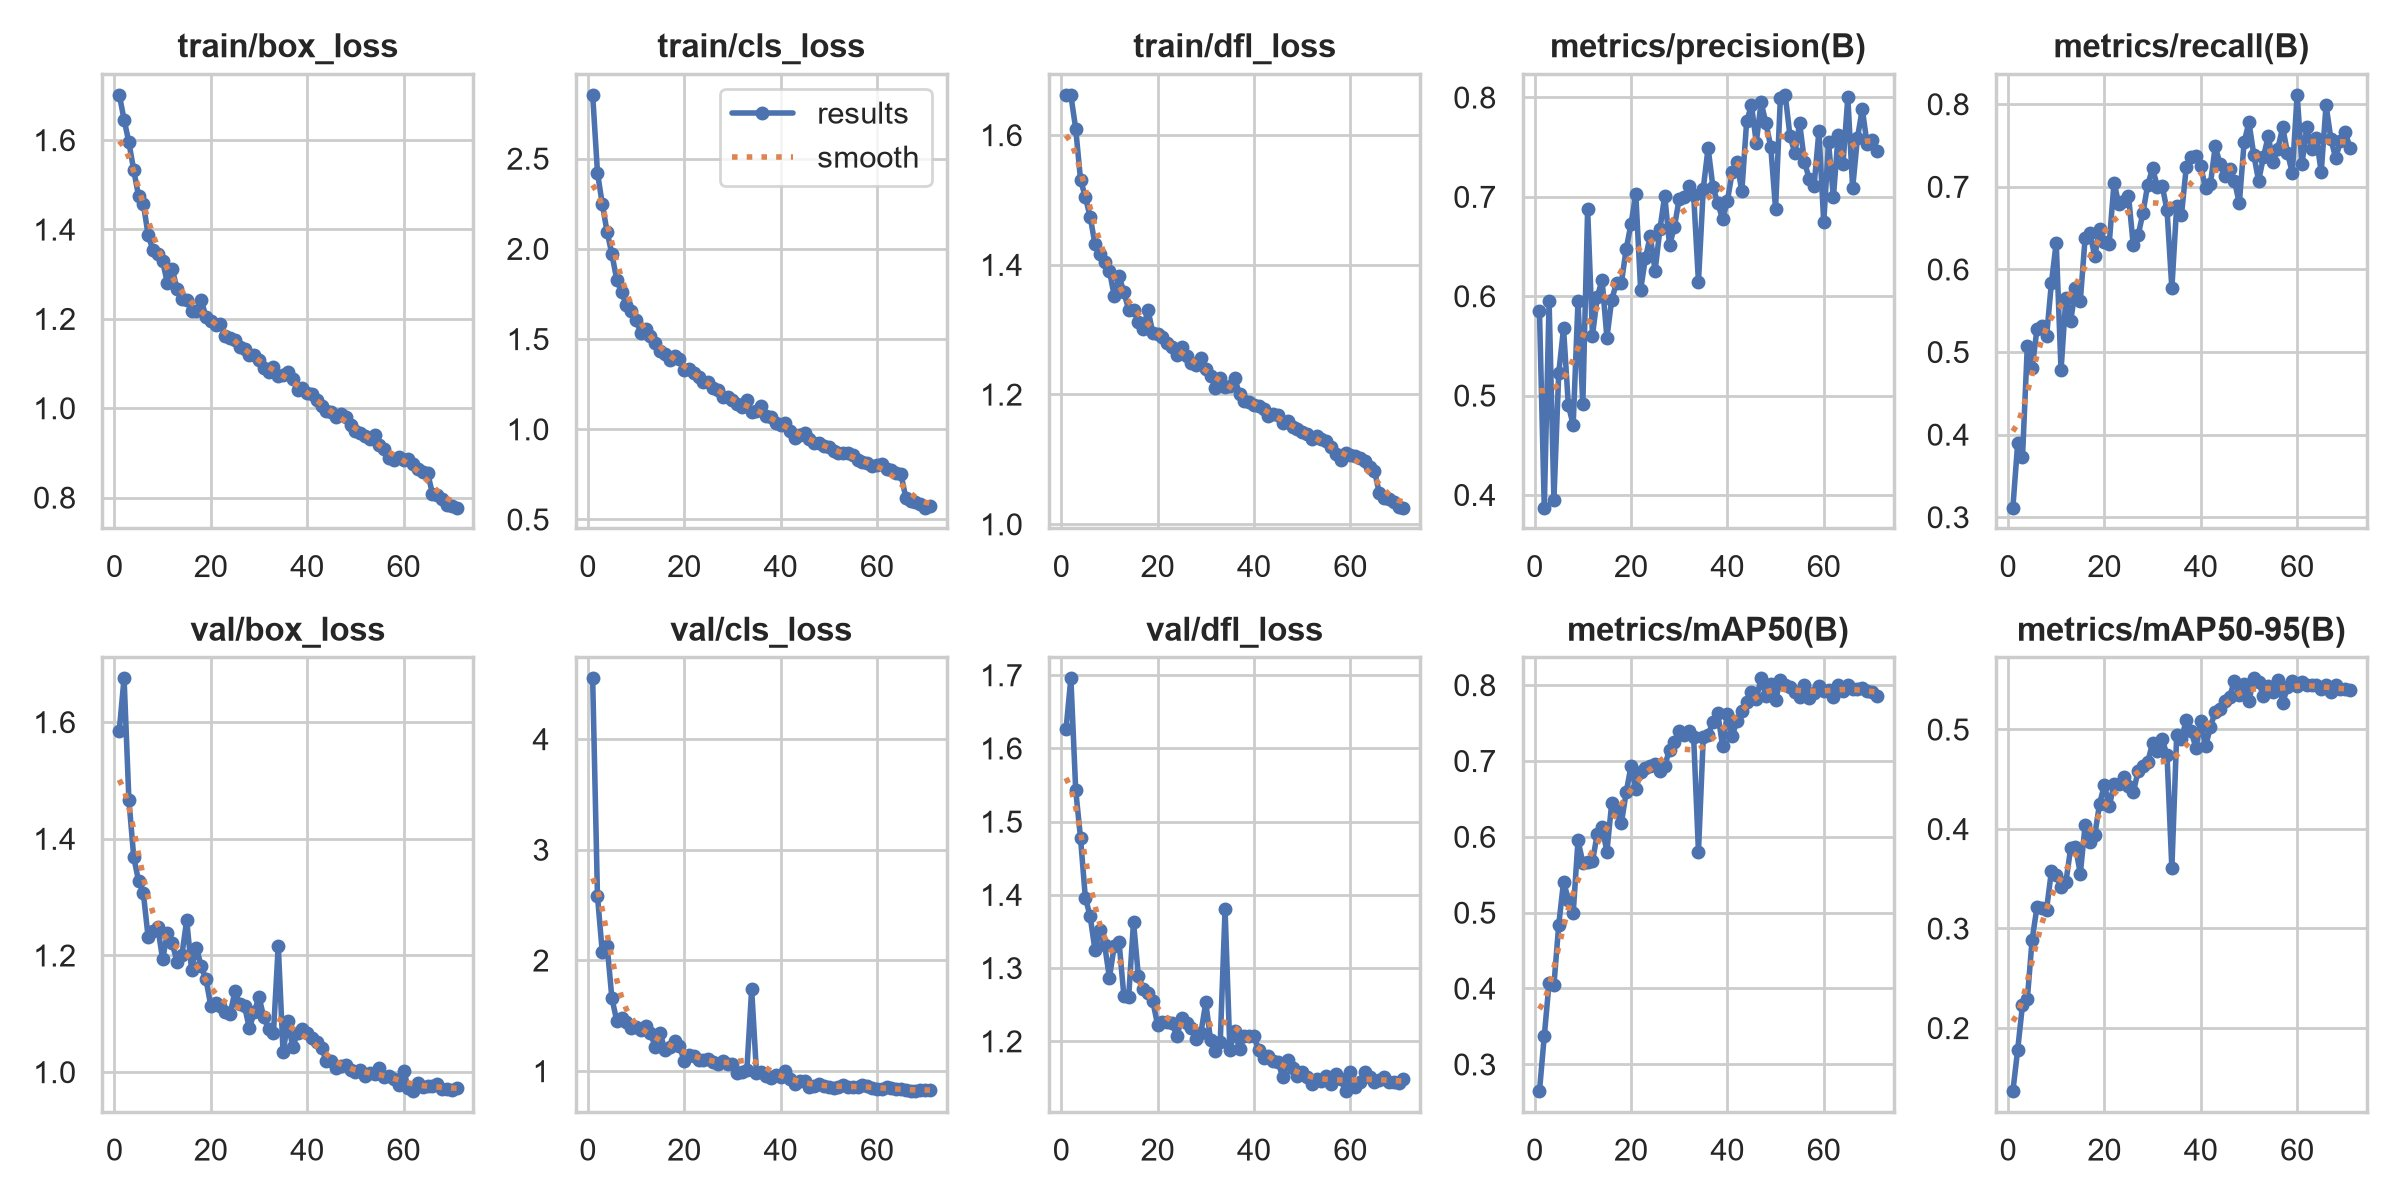

In [9]:
# Courbes de pertes et métriques d'entraînement
history = pd.read_csv(RUN_DIR / "results.csv")
history.columns = history.columns.str.strip()

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for c in [c for c in history if "loss" in c]:
    axes[0].plot(history.epoch, history[c], label=c)
for c in [c for c in history if "mAP" in c]:
    axes[1].plot(history.epoch, history[c], label=c)
for c in [c for c in history if c.endswith("precision(B)") or c.endswith("recall(B)")]:
    axes[2].plot(history.epoch, history[c], label=c)

for ax, title in zip(axes, ["Pertes", "mAP validation", "Précision / Rappel validation"]):
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

if (RUN_DIR / "results.png").exists():
    display(Image.open(RUN_DIR / "results.png"))

## 7. Validation et métriques par classe

Ultralytics 8.4.211  Python-3.12.10 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8151MiB)
YOLO11m summary (fused): 125 layers, 20,036,200 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 68.3±34.1 MB/s, size: 9.3 KB)
val: Scanning C:\Users\firas\OneDrive\Desktop\Projet Douik\pcb_ind_project\raw\PCB-IND_v4\YOLO\labels\val.cache... 478 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 478/478  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 60/60 2.1it/s 29.2s0.2ss3
                   all        478        638      0.821      0.733      0.812      0.551
            mouse_bite         90         99      0.871      0.727      0.839      0.551
        missing_copper        117        218      0.821      0.885      0.931      0.778
               scratch         90         91      0.879       0.89      0.926      0.769
       spurious_copper         41         41      0.7

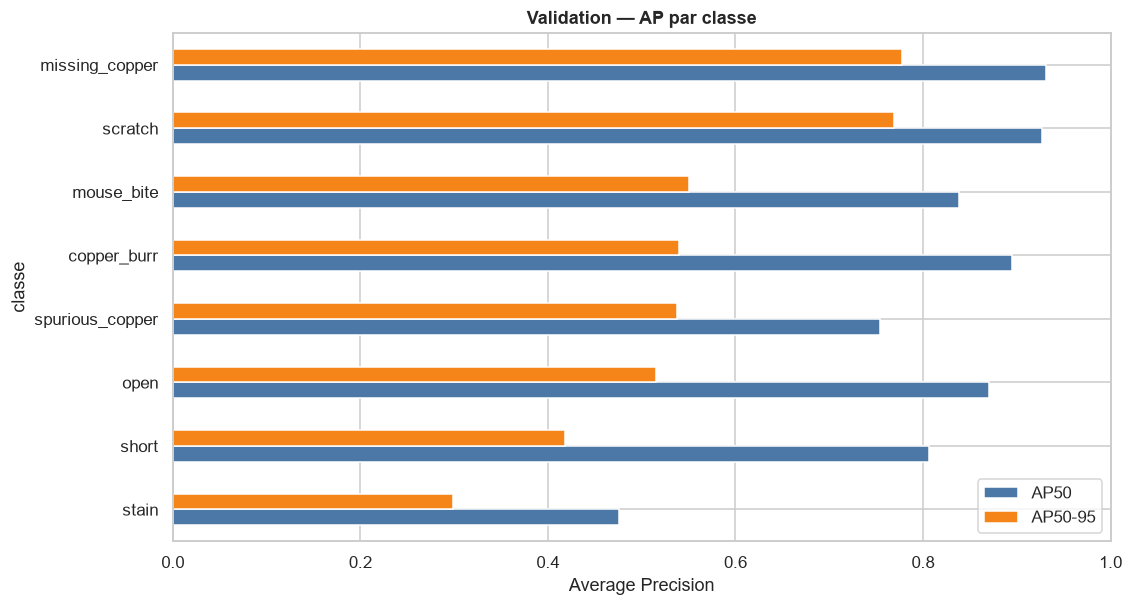

,split,precision_macro,rappel_macro,mAP50,mAP50-95
0,validation,0.820769,0.732695,0.812227,0.550942


In [10]:
# Évaluation sur le jeu de validation
best_model = YOLO(str(BEST_WEIGHTS))
val_metrics = best_model.val(
    data=str(DATA_YAML), split="val", imgsz=640, batch=8, device=DEVICE,
    conf=0.001, iou=0.60, max_det=100, plots=True,
    project=str(RUNS), name=CONFIG["run_name"]+"_val", exist_ok=True,
)

def metrics_overview(metrics, split_name):
    return pd.Series({"split": split_name, "precision_macro": float(metrics.box.mp),
                      "rappel_macro": float(metrics.box.mr),
                      "mAP50": float(metrics.box.map50), "mAP50-95": float(metrics.box.map)})

val_ap = pd.DataFrame({"classe": CLASSES, "AP50": val_metrics.box.ap50, "AP50-95": val_metrics.box.ap})
val_ap = val_ap.sort_values("AP50-95")
val_ap.plot(x="classe", y=["AP50", "AP50-95"], kind="barh", figsize=(11, 6), color=["#4c78a8", "#f58518"])
plt.xlim(0, 1)
plt.title("Validation — AP par classe")
plt.xlabel("Average Precision")
plt.show()

display(metrics_overview(val_metrics, "validation").to_frame().T)

## 8. Optimisation du seuil opérationnel (Validation)

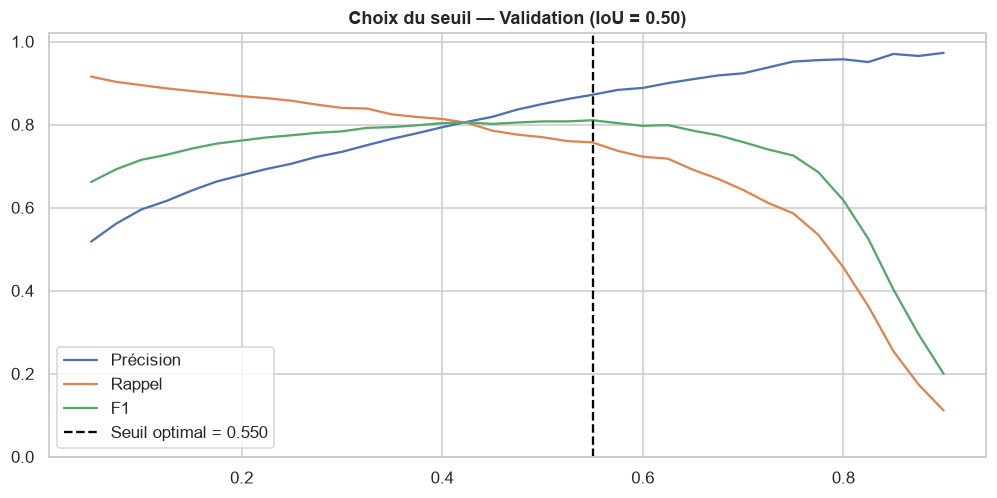

,seuil,precision,recall,f1,tp,fp,fn
validation,0.55,0.871841,0.757053,0.810403,483.0,71.0,155.0


In [11]:
# Calcul de l'IoU et appariement prédictions / vérités terrain
def box_iou_single(box, boxes):
    if len(boxes) == 0:
        return np.empty(0)
    x1 = np.maximum(box[0], boxes[:, 0])
    y1 = np.maximum(box[1], boxes[:, 1])
    x2 = np.minimum(box[2], boxes[:, 2])
    y2 = np.minimum(box[3], boxes[:, 3])
    inter = np.maximum(0, x2 - x1) * np.maximum(0, y2 - y1)
    area_a = (box[2] - box[0]) * (box[3] - box[1])
    area_b = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    return inter / np.maximum(area_a + area_b - inter, 1e-9)

def match_predictions(gt_boxes, gt_classes, pred_boxes, pred_classes, iou_threshold=0.5):
    candidates = []
    for pi, (pb, pc) in enumerate(zip(pred_boxes, pred_classes)):
        same = np.where(gt_classes == pc)[0]
        if len(same):
            for local, iou in enumerate(box_iou_single(pb, gt_boxes[same])):
                if iou >= iou_threshold:
                    candidates.append((float(iou), pi, int(same[local])))
    matched_p, matched_g, tp = set(), set(), 0
    for _, pi, gi in sorted(candidates, reverse=True):
        if pi not in matched_p and gi not in matched_g:
            matched_p.add(pi)
            matched_g.add(gi)
            tp += 1
    return tp, len(pred_boxes) - len(matched_p), len(gt_boxes) - len(matched_g)

def gt_arrays(record):
    if not record["boxes"]:
        return np.empty((0, 4)), np.empty(0, dtype=int)
    xyxy = np.array([yolo_to_xyxy(b)[:4] for b in record["boxes"]], dtype=float)
    cls = np.array([b[0] for b in record["boxes"]], dtype=int)
    return xyxy, cls

def operational_metrics(split_records, predictions, threshold, return_details=False):
    total = Counter()
    details = []
    per_class = {cid: Counter() for cid in range(len(CLASSES))}
    for r, res in zip(split_records, predictions):
        gt, gc = gt_arrays(r)
        if res.boxes is None or len(res.boxes) == 0:
            pb = np.empty((0, 4))
            pc = np.empty(0, dtype=int)
        else:
            keep = res.boxes.conf.cpu().numpy() >= threshold
            pb = res.boxes.xyxy.cpu().numpy()[keep]
            pc = res.boxes.cls.cpu().numpy().astype(int)[keep]
        tp, fp, fn = match_predictions(gt, gc, pb, pc)
        total.update(tp=tp, fp=fp, fn=fn)
        for cid in range(len(CLASSES)):
            gi = np.where(gc == cid)[0]
            pi = np.where(pc == cid)[0]
            ctp, cfp, cfn = match_predictions(gt[gi], gc[gi], pb[pi], pc[pi])
            per_class[cid].update(tp=ctp, fp=cfp, fn=cfn)
        details.append({"image_id": r["image_id"], "tp": tp, "fp": fp, "fn": fn})
    p = total["tp"] / max(total["tp"] + total["fp"], 1)
    r = total["tp"] / max(total["tp"] + total["fn"], 1)
    f = 2 * p * r / max(p + r, 1e-12)
    out = {"precision": p, "recall": r, "f1": f, **total}
    return (out, pd.DataFrame(details), per_class) if return_details else out

# Recherche du seuil optimal maximisant F1 sur validation
val_predictions_raw = best_model.predict(
    source=str(YOLO_ROOT / "images" / "val"), conf=0.001,
    iou=0.50, imgsz=640, device=DEVICE, max_det=100, verbose=False
)
val_by_id = {Path(p.path).stem: p for p in val_predictions_raw}
val_predictions = [val_by_id[r["image_id"]] for r in records["val"]]

rows = [{"seuil": t, **operational_metrics(records["val"], val_predictions, t)}
        for t in np.arange(0.05, 0.901, 0.025)]
threshold_df = pd.DataFrame(rows)
best_row = threshold_df.loc[threshold_df.f1.idxmax()]
BEST_CONF = float(best_row.seuil)

fig, ax = plt.subplots(figsize=(11, 5))
for c, label in [("precision", "Précision"), ("recall", "Rappel"), ("f1", "F1")]:
    ax.plot(threshold_df.seuil, threshold_df[c], label=label)
ax.axvline(BEST_CONF, color="black", ls="--", label=f"Seuil optimal = {BEST_CONF:.3f}")
ax.set_ylim(0, 1.02)
ax.set_title("Choix du seuil — Validation (IoU = 0.50)")
ax.legend()
plt.show()

display(best_row.to_frame("validation").T)

## 9. Évaluation sur l'ensemble de Test

Ultralytics 8.4.211  Python-3.12.10 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8151MiB)
YOLO11m summary (fused): 125 layers, 20,036,200 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 50.3±20.0 MB/s, size: 6.9 KB)
val: Scanning C:\Users\firas\OneDrive\Desktop\Projet Douik\pcb_ind_project\raw\PCB-IND_v4\YOLO\labels\test.cache... 478 images, 9 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 478/478  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 60/60 2.1it/s 28.6s0.2s
                   all        478        547      0.726      0.665      0.723      0.497
            mouse_bite         87         91      0.693      0.669      0.733      0.474
        missing_copper        105        132      0.669      0.886      0.877      0.688
               scratch         90         92      0.897      0.666      0.898      0.638
       spurious_copper         43         43      0.68

,split,precision_macro,rappel_macro,mAP50,mAP50-95
0,validation,0.820769,0.732695,0.812227,0.550942
1,test,0.726231,0.665266,0.72336,0.497255


confusion_matrix_normalized.png


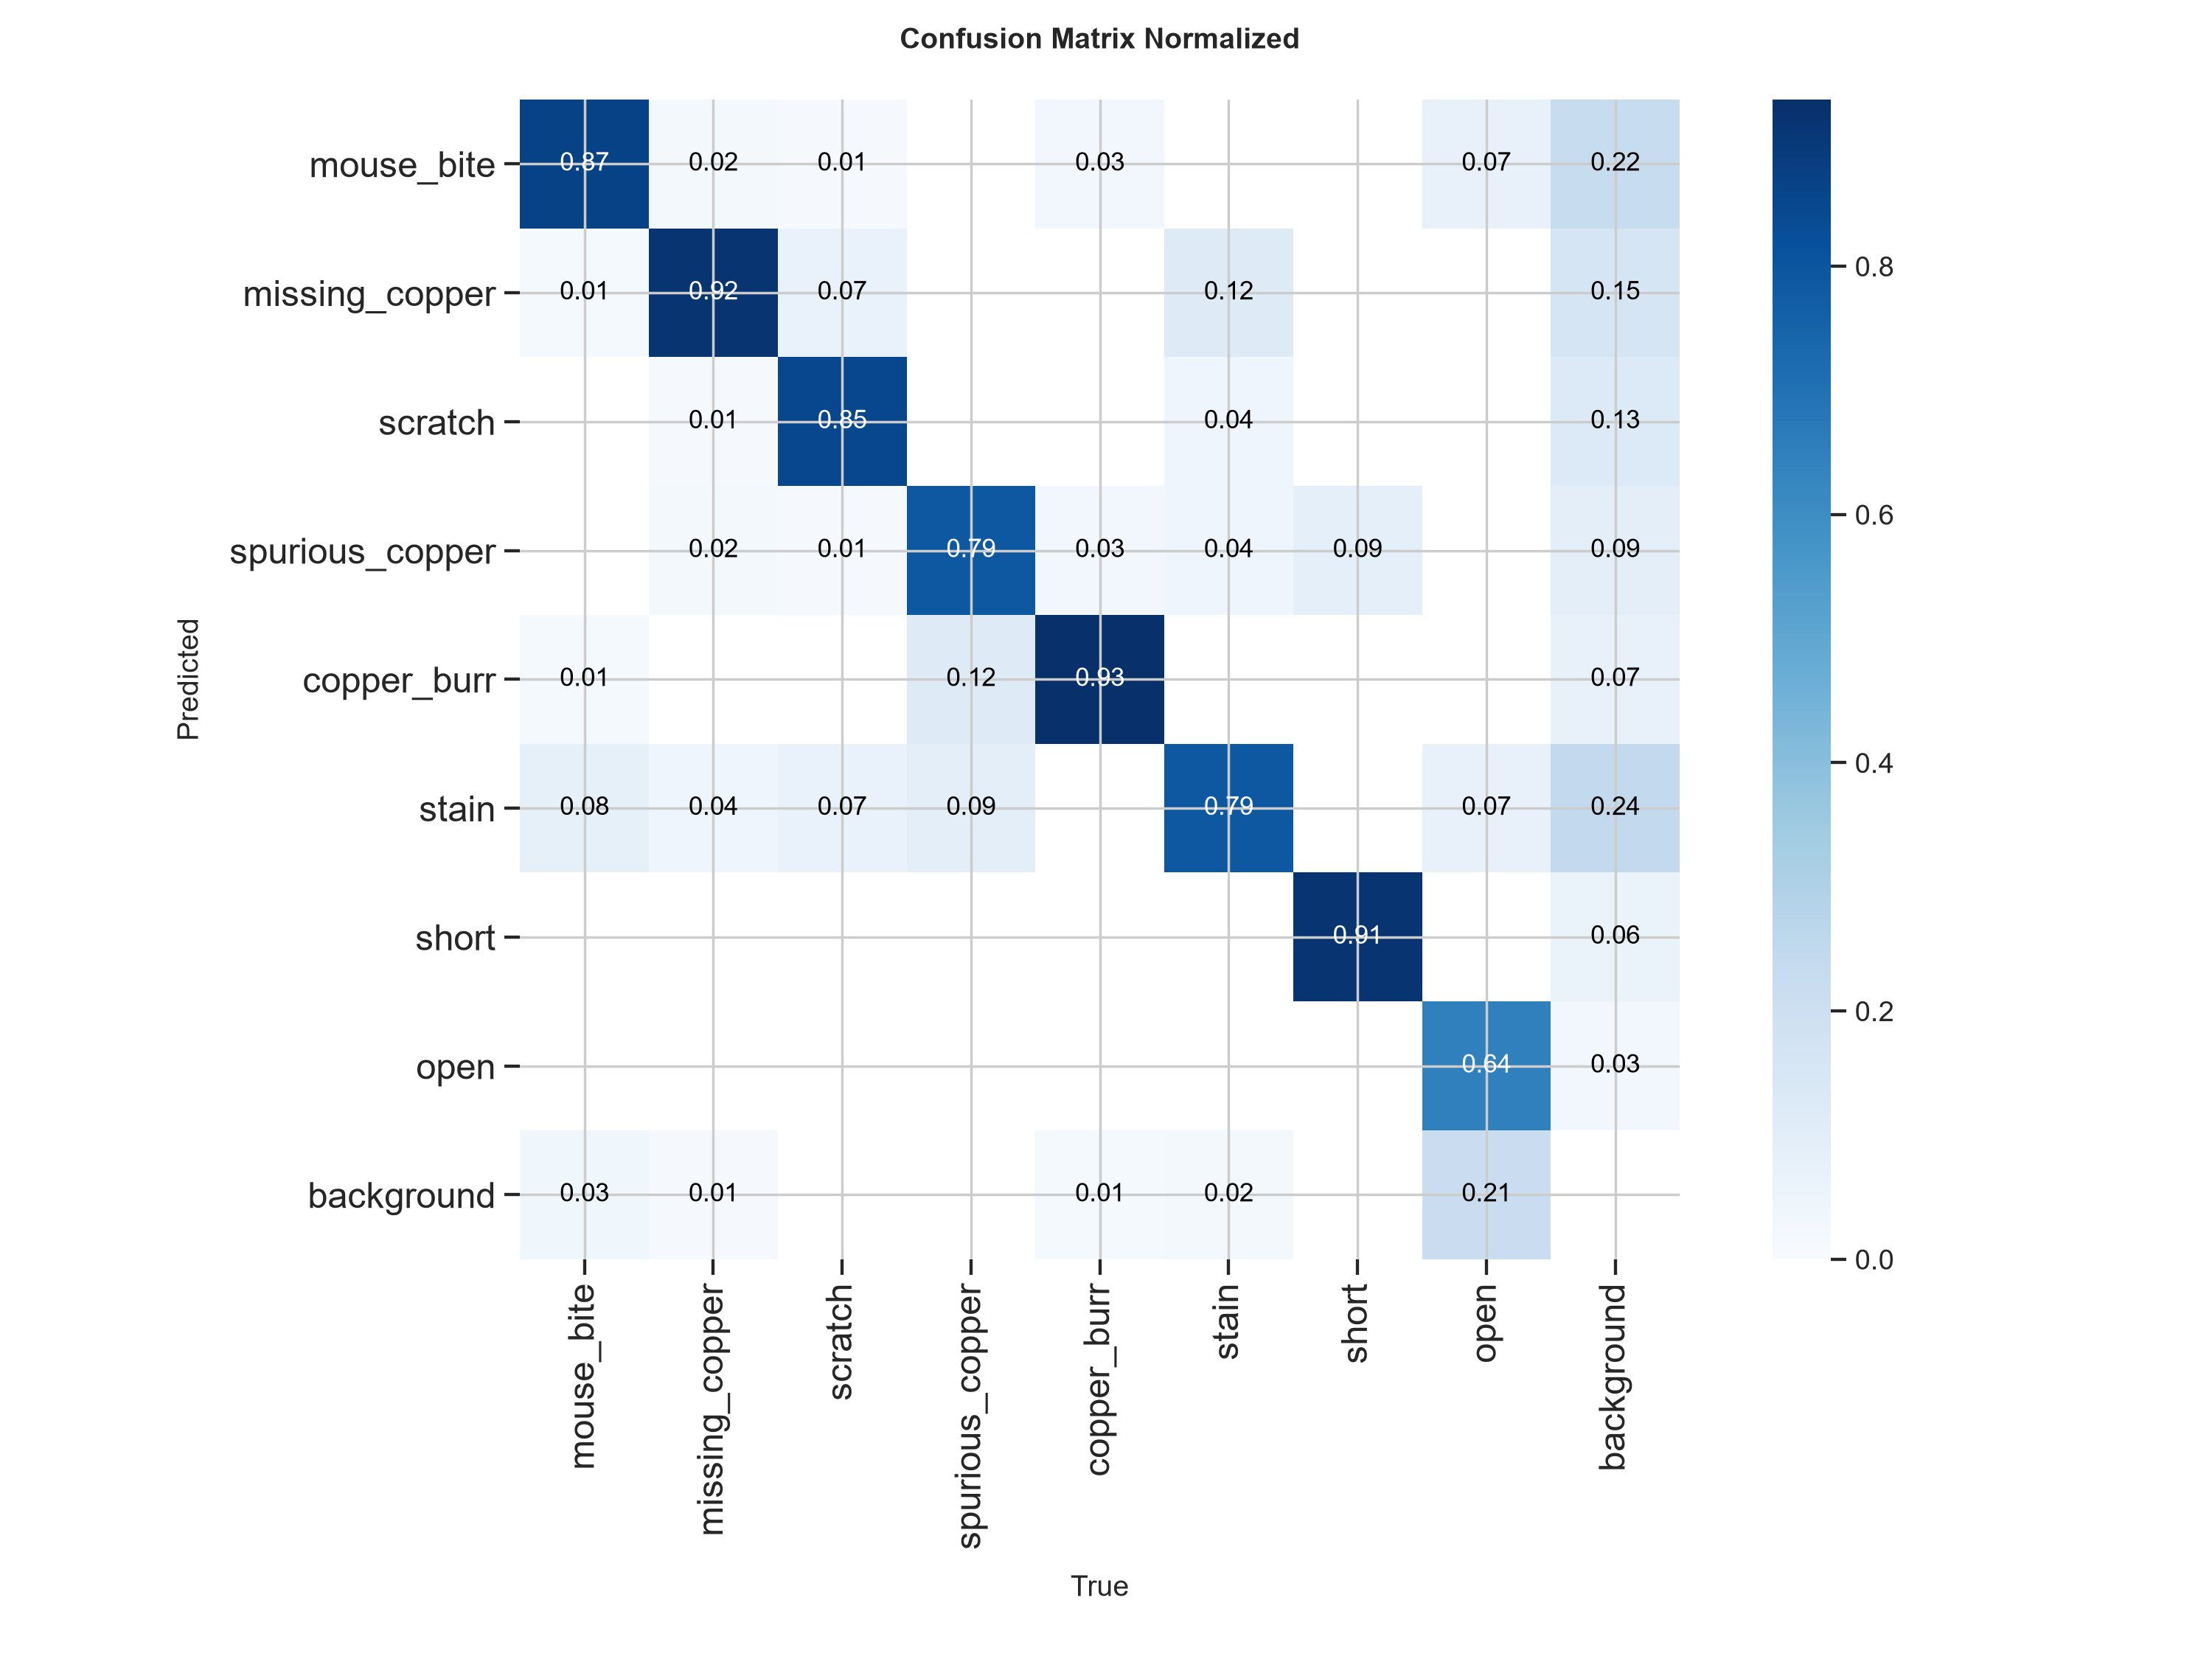

Test au seuil opérationnel (0.550) :


,precision,recall,f1,tp,fp,fn
test,0.841584,0.621572,0.715037,340.0,64.0,207.0


,classe,precision,rappel,F1,tp,fp,fn
0,mouse_bite,0.822581,0.560440,0.666667,51,11,40
1,missing_copper,0.830645,0.780303,0.804688,103,21,29
2,scratch,0.979592,0.521739,0.680851,48,1,44
3,spurious_copper,0.766667,0.534884,0.630137,23,7,20
4,copper_burr,0.849315,0.815789,0.832215,62,11,14
5,stain,0.720000,0.346154,0.467532,18,7,34
6,short,0.837838,0.659574,0.738095,31,6,16
7,open,1.000000,0.285714,0.444444,4,0,10


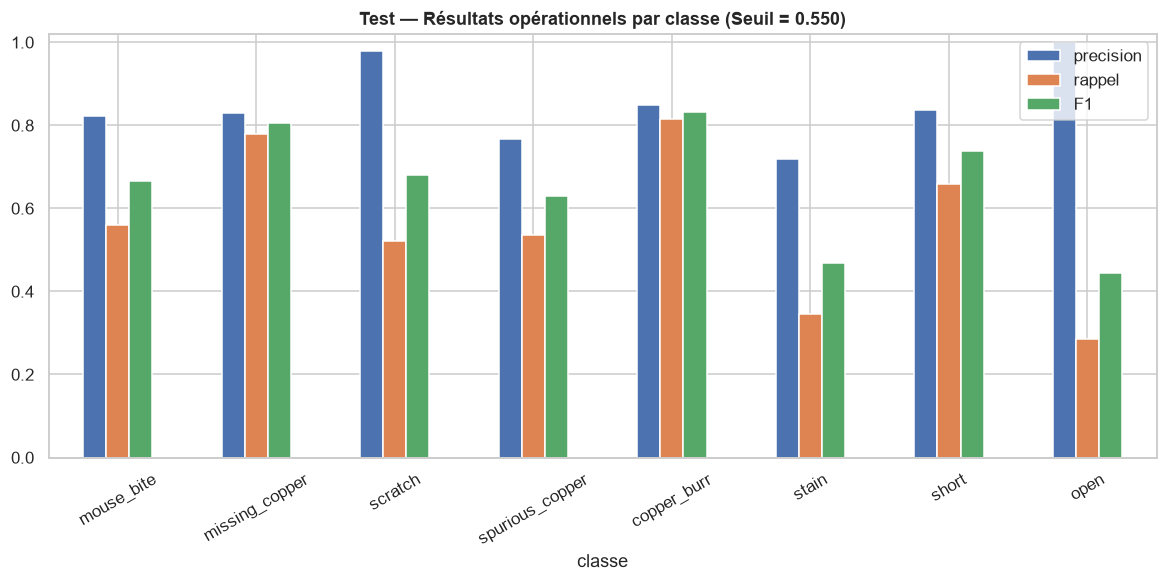

In [12]:
# Évaluation finale sur l'ensemble de test officiel
test_metrics = best_model.val(
    data=str(DATA_YAML), split="test", imgsz=640, batch=8, device=DEVICE,
    conf=0.001, iou=0.60, max_det=100, plots=True,
    project=str(RUNS), name=CONFIG["run_name"]+"_test", exist_ok=True
)
overview = pd.concat([metrics_overview(val_metrics, "validation"), metrics_overview(test_metrics, "test")], axis=1).T
display(overview)

TEST_DIR = RUNS / (CONFIG["run_name"] + "_test")
for name in ["PR_curve.png", "F1_curve.png", "confusion_matrix_normalized.png"]:
    if (TEST_DIR / name).exists():
        print(name)
        display(Image.open(TEST_DIR / name))

# Évaluation opérationnelle au seuil optimal
test_raw = best_model.predict(
    source=str(YOLO_ROOT / "images" / "test"), conf=0.001,
    iou=0.50, imgsz=640, device=DEVICE, max_det=100, verbose=False
)
test_by_id = {Path(p.path).stem: p for p in test_raw}
test_predictions = [test_by_id[r["image_id"]] for r in records["test"]]
test_operational, test_details, test_per_class = operational_metrics(
    records["test"], test_predictions, BEST_CONF, True
)

class_rows = []
for cid, c in test_per_class.items():
    p = c["tp"] / max(c["tp"] + c["fp"], 1)
    r = c["tp"] / max(c["tp"] + c["fn"], 1)
    f = 2 * p * r / max(p + r, 1e-12)
    class_rows.append({"classe": CLASSES[cid], "precision": p, "rappel": r, "F1": f, **c})
class_operational = pd.DataFrame(class_rows)

print(f"Test au seuil opérationnel ({BEST_CONF:.3f}) :")
display(pd.Series(test_operational, name="test").to_frame().T)
display(class_operational)

class_operational.set_index("classe")[["precision", "rappel", "F1"]].plot(kind="bar", figsize=(13, 5), ylim=(0, 1.02))
plt.title(f"Test — Résultats opérationnels par classe (Seuil = {BEST_CONF:.3f})")
plt.xticks(rotation=30)
plt.show()

## 10. Analyse qualitative et cas difficiles

  5831_b_001 : 1 détections restantes
  6504_b_001 : 0 détections restantes
  5831_b_002 : 1 détections restantes
  6334_t_007 : 0 détections restantes
  6334_t_097 : 0 détections restantes
  6216_t_007 : 1 détections restantes


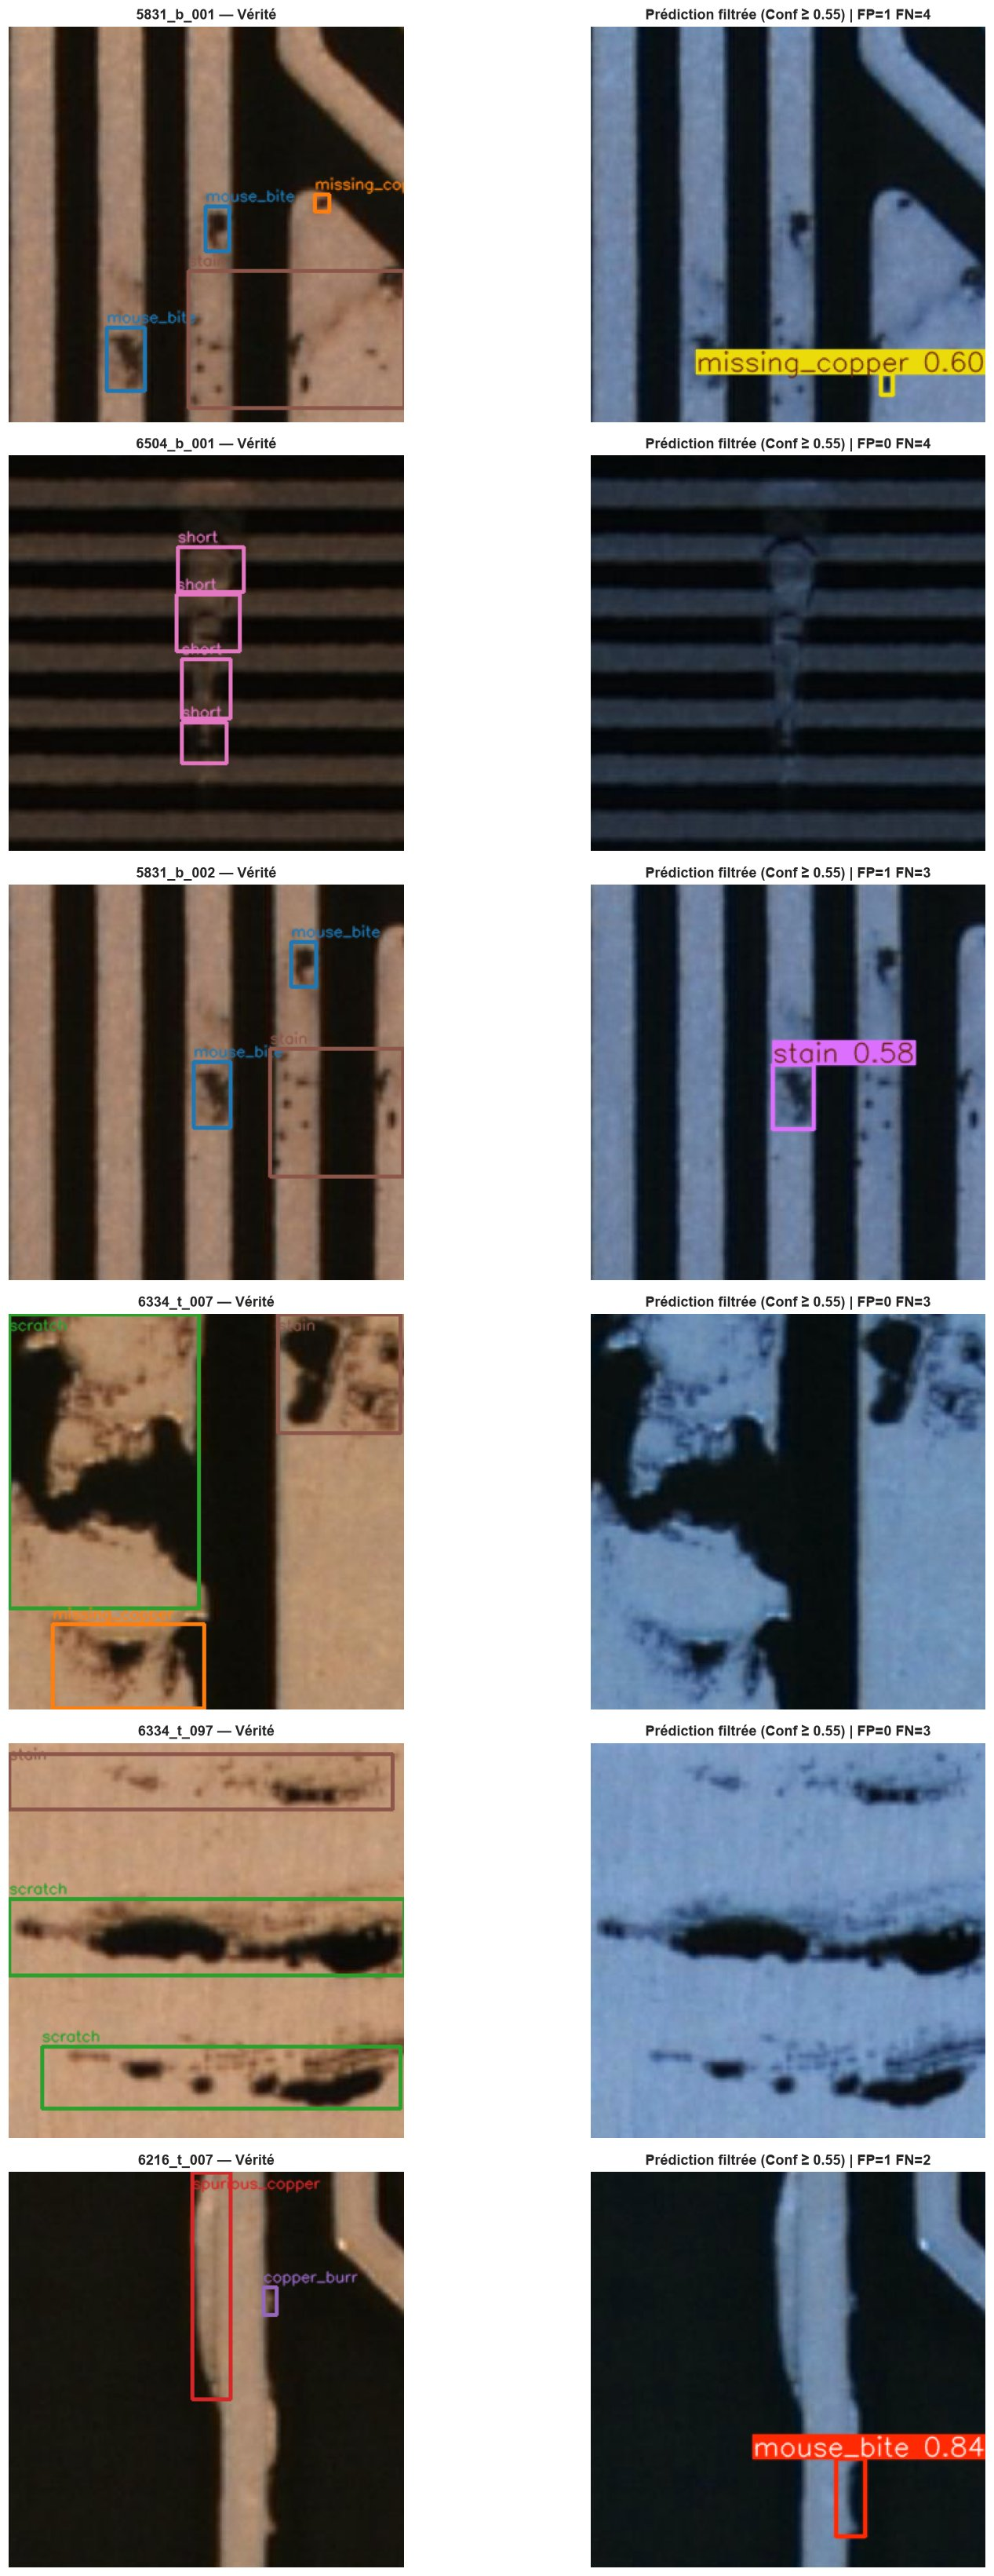

In [13]:
# Dictionnaires de test et analyse des cas difficiles
record_by_id = {r["image_id"]: r for r in records["test"]}
pred_by_id = {r["image_id"]: p for r, p in zip(records["test"], test_predictions)}
test_details["erreurs"] = test_details.fp + test_details.fn

CONF_MIN = 0.55
IOU_MAX = 0.15

def nms_strict(boxes, scores, iou_thresh):
    if len(boxes) == 0:
        return []
    b = np.array(boxes)
    s = np.array(scores)
    x1, y1, x2, y2 = b[:, 0], b[:, 1], b[:, 2], b[:, 3]
    areas = (x2 - x1) * (y2 - y1)
    order = s.argsort()[::-1]
    keep = []
    while order.size > 0:
        i = order[0]
        keep.append(i)
        xx1 = np.maximum(x1[i], x1[order[1:]])
        yy1 = np.maximum(y1[i], y1[order[1:]])
        xx2 = np.minimum(x2[i], x2[order[1:]])
        yy2 = np.minimum(y2[i], y2[order[1:]])
        inter = np.maximum(0, xx2 - xx1) * np.maximum(0, yy2 - yy1)
        ovr = inter / (areas[i] + areas[order[1:]] - inter + 1e-6)
        order = order[np.where(ovr <= iou_thresh)[0] + 1]
    return keep

def filtrer_strict(p):
    if hasattr(p, "boxes") and hasattr(p.boxes, "conf"):
        conf = p.boxes.conf.cpu().numpy()
        boxes = p.boxes.xyxy.cpu().numpy()
        valides = np.where(conf >= CONF_MIN)[0]
        if len(valides) == 0:
            return p[np.array([], dtype=int)]
        keep = nms_strict(boxes[valides], conf[valides], IOU_MAX)
        return p[valides[keep]]
    return p

clean = {k: filtrer_strict(v) for k, v in pred_by_id.items()}

# Affichage des cas d'erreurs principaux
hard_ids = test_details.sort_values(["erreurs", "fn"], ascending=False).head(6).image_id.tolist()
for img_id in hard_ids:
    c = clean[img_id]
    n = len(c.boxes) if hasattr(c, "boxes") else "?"
    print(f"  {img_id} : {n} détections restantes")

fig, axes = plt.subplots(len(hard_ids), 2, figsize=(16, 5 * len(hard_ids)))
for row, image_id in enumerate(hard_ids):
    draw_ground_truth(record_by_id[image_id], axes[row, 0], image_id + " — Vérité")
    pred_filtre = clean[image_id]
    if hasattr(pred_filtre, "plot"):
        img_plot = pred_filtre.plot(conf=True, line_width=2, font_size=10, pil=False)
        axes[row, 1].imshow(img_plot)
    axes[row, 1].axis("off")
    stats = test_details[test_details.image_id == image_id].iloc[0]
    axes[row, 1].set_title(f"Prédiction filtrée (Conf ≥ {CONF_MIN}) | FP={int(stats.fp)} FN={int(stats.fn)}")

plt.tight_layout()
plt.show()

## 11. Système de décision floue (Mamdani)

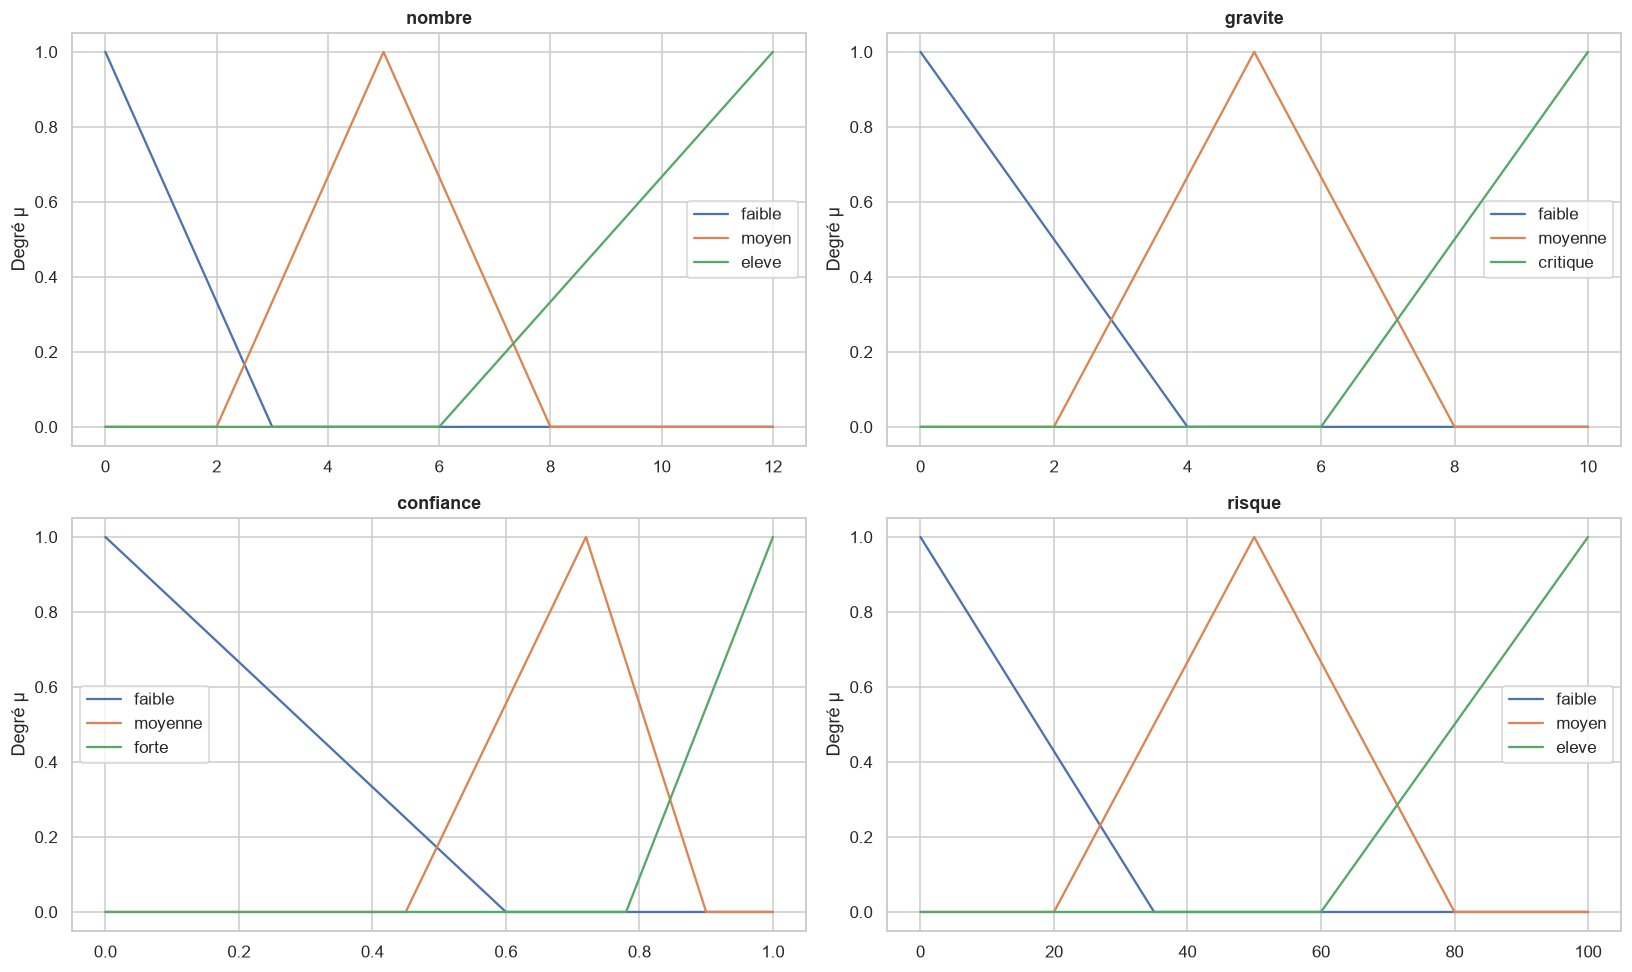

,nombre,gravite,confiance,risque,decision
0,0,0.0,1.00,0.000000,ACCEPTER — Carte 100% conforme
1,1,2.0,0.95,80.000000,REJETER — Carte défectueuse (stain)
2,1,10.0,0.95,86.105499,REJETER — Carte défectueuse (short)
3,7,5.0,0.82,80.000000,REJETER — Carte défectueuse (mouse_bite)


In [82]:
# Définition des variables floues et fonctions d'appartenance
nombre = ctrl.Antecedent(np.arange(0, 13, 1), "nombre")
gravite = ctrl.Antecedent(np.arange(0, 10.1, 0.1), "gravite")
confiance = ctrl.Antecedent(np.arange(0, 1.01, 0.01), "confiance")
risque = ctrl.Consequent(np.arange(0, 101, 1), "risque")

nombre["faible"] = fuzz.trimf(nombre.universe, [0, 0, 3])
nombre["moyen"] = fuzz.trimf(nombre.universe, [2, 5, 8])
nombre["eleve"] = fuzz.trimf(nombre.universe, [6, 12, 12])

gravite["faible"] = fuzz.trimf(gravite.universe, [0, 0, 4])
gravite["moyenne"] = fuzz.trimf(gravite.universe, [2, 5, 8])
gravite["critique"] = fuzz.trimf(gravite.universe, [6, 10, 10])

confiance["faible"] = fuzz.trimf(confiance.universe, [0, 0, 0.60])
confiance["moyenne"] = fuzz.trimf(confiance.universe, [0.45, 0.72, 0.90])
confiance["forte"] = fuzz.trimf(confiance.universe, [0.78, 1, 1])

risque["faible"] = fuzz.trimf(risque.universe, [0, 0, 35])
risque["moyen"] = fuzz.trimf(risque.universe, [20, 50, 80])
risque["eleve"] = fuzz.trimf(risque.universe, [60, 100, 100])

# Base de règles Mamdani
rules = [
    ctrl.Rule(gravite["critique"] & confiance["forte"], risque["eleve"]),
    ctrl.Rule(gravite["critique"] & confiance["moyenne"], risque["eleve"]),
    ctrl.Rule(gravite["critique"] & confiance["faible"], risque["moyen"]),
    ctrl.Rule(gravite["moyenne"] & nombre["eleve"], risque["eleve"]),
    ctrl.Rule(gravite["moyenne"] & nombre["moyen"], risque["moyen"]),
    ctrl.Rule(gravite["moyenne"] & nombre["faible"], risque["moyen"]),
    ctrl.Rule(gravite["faible"] & nombre["eleve"], risque["moyen"]),
    ctrl.Rule(gravite["faible"] & nombre["moyen"], risque["moyen"]),
    ctrl.Rule(gravite["faible"] & nombre["faible"] & ~confiance["faible"], risque["faible"]),
    ctrl.Rule(gravite["faible"] & nombre["faible"] & confiance["faible"], risque["moyen"]),
    ctrl.Rule(nombre["eleve"] & confiance["forte"], risque["eleve"]),
]
quality_ctrl = ctrl.ControlSystem(rules)

# Tracé des fonctions d'appartenance
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for variable, ax in zip([nombre, gravite, confiance, risque], axes.flat):
    for label in variable.terms:
        ax.plot(variable.universe, variable[label].mf, label=label)
    ax.set_title(variable.label)
    ax.set_ylabel("Degré μ")
    ax.legend()
plt.tight_layout()
plt.show()

# Poids de gravité par classe de défaut
SEVERITY = {
    "mouse_bite": 5.0, "missing_copper": 8.0, "scratch": 4.0, "spurious_copper": 7.0,
    "copper_burr": 6.0, "stain": 2.0, "short": 10.0, "open": 9.0
}

def fuzzy_decision(detections):
    """Moteur de décision industriel — Tolérance Zéro (Rejet Direct).
    - Tout défaut détecté (même à 10%) = REJETER la carte.
    - 0 défaut détecté = ACCEPTER (Carte 100% conforme)."""
    if not detections:
        return {"nombre": 0, "gravite": 0.0, "confiance": 1.0, "risque": 0.0,
                "decision": "ACCEPTER — Carte 100% conforme"}

    n = len(detections)
    severity = max(SEVERITY[d["classe"]] for d in detections)
    confidence = float(np.mean([d["confiance"] for d in detections]))
    classes_str = ", ".join(sorted(set(d["classe"] for d in detections)))
    
    # Calcul du risque flou pour archivage
    sim = ctrl.ControlSystemSimulation(quality_ctrl)
    sim.input["nombre"] = min(n, 12)
    sim.input["gravite"] = severity
    sim.input["confiance"] = min(confidence, 1.0)
    sim.compute()
    risk = max(float(sim.output["risque"]), 80.0)

    return {
        "nombre": n, "gravite": severity, "confiance": confidence,
        "risque": risk,
        "decision": f"REJETER — Carte défectueuse ({classes_str})"
    }

# Validation sur scénarios tests
display(pd.DataFrame([fuzzy_decision(s) for s in [
    [],
    [{"classe": "stain", "confiance": 0.95}],
    [{"classe": "short", "confiance": 0.95}],
    [{"classe": "mouse_bite", "confiance": 0.82}] * 7,
]]))

## 12. Inférence et qualification des cartes

Image sélectionnée : 6187_b_001.jpg


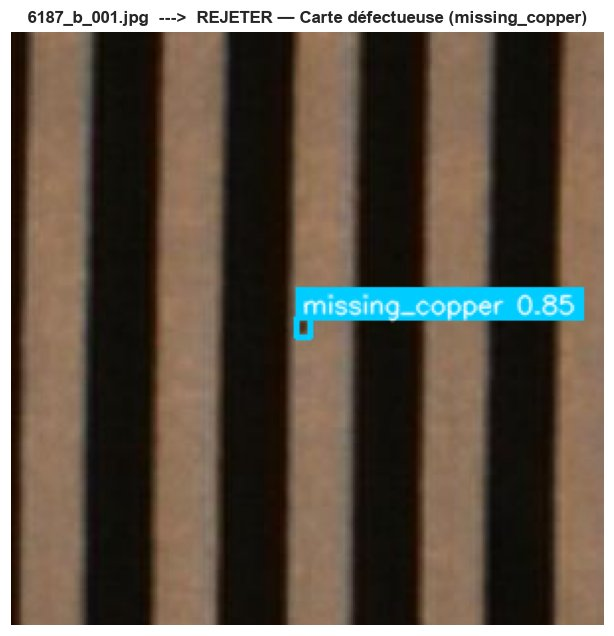

,classe,confiance
0,missing_copper,0.853211


Détail décision : {'nombre': 1, 'gravite': 8.0, 'confiance': 0.8532105088233948, 'risque': 83.10634611153706, 'decision': 'REJETER — Carte défectueuse (missing_copper)'}


In [98]:
# Inférence complète (YOLO + Logique Floue) avec filtrage anti-collision
def clean_and_deduplicate_boxes(boxes, scores, classes, names, overlap_thresh=0.30):
    if len(boxes) == 0:
        return []
    dets = []
    for b, s, c in zip(boxes, scores, classes):
        dets.append({"box": [float(x) for x in b], "confiance": float(s),
                     "cls_id": int(c), "classe": names[int(c)]})
    dets.sort(key=lambda x: x["confiance"], reverse=True)
    kept = []
    for d in dets:
        b1 = d["box"]
        area1 = (b1[2] - b1[0]) * (b1[3] - b1[1])
        suppress = False
        for k in kept:
            b2 = k["box"]
            area2 = (b2[2] - b2[0]) * (b2[3] - b2[1])
            xx1, yy1 = max(b1[0], b2[0]), max(b1[1], b2[1])
            xx2, yy2 = min(b1[2], b2[2]), min(b1[3], b2[3])
            w, h = max(0.0, xx2 - xx1), max(0.0, yy2 - yy1)
            inter = w * h
            if inter > 0:
                min_area = min(area1, area2)
                ioa = inter / (min_area + 1e-6)
                iou = inter / (area1 + area2 - inter + 1e-6)
                if ioa > overlap_thresh or iou > 0.20:
                    suppress = True
                    break
        if not suppress:
            kept.append(d)
    return kept

def draw_boxes_clean(img_rgb, detections):
    canvas = img_rgb.copy()
    h_img, w_img = canvas.shape[:2]
    COLORS = {
        'mouse_bite': (0, 102, 255), 'missing_copper': (0, 204, 255), 'scratch': (255, 255, 255),
        'spurious_copper': (0, 255, 128), 'copper_burr': (255, 128, 0), 'stain': (255, 51, 153),
        'short': (255, 0, 0), 'open': (204, 0, 204)
    }
    used_labels = []
    for d in detections:
        b, cls_name, conf = d['box'], d['classe'], d['confiance']
        color = COLORS.get(cls_name, (0, 255, 0))
        x1, y1, x2, y2 = [int(v) for v in b]
        cv2.rectangle(canvas, (x1, y1), (x2, y2), color, 2)
        label = f"{cls_name} {conf:.2f}"
        font, scale, thick = cv2.FONT_HERSHEY_SIMPLEX, 0.42, 1
        (tw, th), _ = cv2.getTextSize(label, font, scale, thick)
        lx1, ly1 = x1, y1 - th - 5
        lx2, ly2 = lx1 + tw + 6, y1
        if ly1 < 0:
            ly1, ly2 = y2, y2 + th + 6
        for shift in [0, th + 8, -(th + 8), 2*(th + 8)]:
            t_ly1 = max(0, min(h_img - th - 6, ly1 + shift))
            t_ly2 = t_ly1 + th + 6
            if not any(not (lx2 < rx1 or lx1 > rx2 or t_ly2 < ry1 or t_ly1 > ry2) for rx1, ry1, rx2, ry2 in used_labels):
                ly1, ly2 = t_ly1, t_ly2
                break
        used_labels.append((lx1, ly1, lx2, ly2))
        cv2.rectangle(canvas, (lx1, ly1), (lx2, ly2), color, -1)
        text_color = (0, 0, 0) if (color[0]*0.299 + color[1]*0.587 + color[2]*0.114) > 150 else (255, 255, 255)
        cv2.putText(canvas, label, (lx1 + 3, ly2 - 3), font, scale, text_color, thick, cv2.LINE_AA)
    return canvas

dossier_test = RAW / "PCB-IND_v4" / "YOLO" / "images" / "test"
images_test = list(dossier_test.glob("*.jpg"))
img_path = random.choice(images_test)
print("Image sélectionnée :", img_path.name)

result = best_model.predict(source=str(img_path), imgsz=640, conf=0.20, iou=0.35, agnostic_nms=True, augment=True, verbose=False)[0]
boxes = result.boxes.xyxy.cpu().numpy() if result.boxes is not None else []
scores = result.boxes.conf.cpu().numpy() if result.boxes is not None else []
classes = result.boxes.cls.cpu().numpy().astype(int) if result.boxes is not None else []

detections = clean_and_deduplicate_boxes(boxes, scores, classes, CLASSES)
decision = fuzzy_decision(detections)

img_bgr = cv2.imread(str(img_path))
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
annotated = draw_boxes_clean(img_rgb, detections)

plt.figure(figsize=(7, 7))
plt.imshow(annotated)
plt.title(f"{img_path.name}  --->  {decision['decision']}", fontsize=11, fontweight='bold')
plt.axis("off")
plt.show()

if detections:
    display(pd.DataFrame(detections)[['classe', 'confiance']])
else:
    print("Aucun défaut détecté — Carte 100% conforme.")

print("Détail décision :", decision)

In [ ]:
# Test d'images personnalisées (Colab ou dossier local)
try:
    from google.colab import files
    has_colab = True
except ImportError:
    has_colab = False

external_model = YOLO(str(BEST_WEIGHTS))
UPLOAD_DIR = BASE / "mes_images_pcb_ind"
UPLOAD_DIR.mkdir(exist_ok=True)

if has_colab:
    uploaded = files.upload()
else:
    local_images = [p for p in UPLOAD_DIR.glob("*.*")
                    if p.suffix.lower() in {".jpg", ".jpeg", ".png"} and not p.stem.endswith("_prediction")]
    uploaded = {p.name: p.read_bytes() for p in local_images}
    if not uploaded:
        print(f"Mode local : déposer des images .jpg ou .png dans {UPLOAD_DIR} pour tester.")

external_rows = []
for filename, content in uploaded.items():
    if Path(filename).suffix.lower() not in {".jpg", ".jpeg", ".png"}:
        continue
    path = UPLOAD_DIR / Path(filename).name
    path.write_bytes(content)

    res = external_model.predict(str(path), imgsz=640, conf=0.20, iou=0.35, agnostic_nms=True, augment=True,
                                 device=DEVICE, max_det=100, verbose=False)[0]
    boxes = res.boxes.xyxy.cpu().numpy() if res.boxes is not None else []
    scores = res.boxes.conf.cpu().numpy() if res.boxes is not None else []
    classes = res.boxes.cls.cpu().numpy().astype(int) if res.boxes is not None else []

    detections = clean_and_deduplicate_boxes(boxes, scores, classes, CLASSES)
    decision = fuzzy_decision(detections)

    img_bgr = cv2.imread(str(path))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    annotated = draw_boxes_clean(img_rgb, detections)

    plt.figure(figsize=(7, 7))
    plt.imshow(annotated)
    plt.title(f"{path.name} — {decision['decision']}", fontsize=10, fontweight='bold')
    plt.axis("off")
    plt.show()

    if detections:
        display(pd.DataFrame(detections)[['classe', 'confiance']])
    cv2.imwrite(str(UPLOAD_DIR / f"{path.stem}_prediction.jpg"), cv2.cvtColor(annotated, cv2.COLOR_RGB2BGR))
    external_rows.append({"image": path.name, "classes": ", ".join(d["classe"] for d in detections), **decision})

if external_rows:
    external_report = pd.DataFrame(external_rows)
    display(external_report)
    external_report.to_csv(UPLOAD_DIR / "rapport.csv", index=False)

## 13. Benchmark de latence et export des livrables

In [17]:
# Mesure de latence batch=1 et export des livrables
benchmark = records["test"][:50]
for r in benchmark[:5]:
    best_model.predict(str(r["image"]), imgsz=640, conf=BEST_CONF, device=DEVICE, verbose=False)
if torch.cuda.is_available():
    torch.cuda.synchronize()

start = time.perf_counter()
for r in benchmark:
    best_model.predict(str(r["image"]), imgsz=640, conf=BEST_CONF, device=DEVICE, verbose=False)
if torch.cuda.is_available():
    torch.cuda.synchronize()
latency_ms = 1000 * (time.perf_counter() - start) / len(benchmark)
print(f"Latence indicative batch=1 : {latency_ms:.2f} ms/image")

shutil.copy2(BEST_WEIGHTS, EXPORTS / "best.pt")
shutil.copy2(DATA_YAML, EXPORTS / "data.yaml")
(EXPORTS / "config.json").write_text(json.dumps(CONFIG, indent=2))
history.to_csv(EXPORTS / "training_history.csv", index=False)
threshold_df.to_csv(EXPORTS / "validation_thresholds.csv", index=False)
overview.to_csv(EXPORTS / "map_metrics.csv", index=False)
class_operational.to_csv(EXPORTS / "test_by_class.csv", index=False)
test_details.to_csv(EXPORTS / "test_errors.csv", index=False)

final_metrics = {"model": CONFIG["model"], "profile": PROFILE, "threshold": BEST_CONF,
                 "test_operational": test_operational, "latency_ms": latency_ms,
                 "mAP50": float(test_metrics.box.map50), "mAP50-95": float(test_metrics.box.map)}
(EXPORTS / "final_metrics.json").write_text(json.dumps(final_metrics, indent=2))
archive = shutil.make_archive(str(BASE / "PCB_IND_livrables"), "zip", EXPORTS)
print("Archive livrables :", archive)

Latence indicative batch=1 : 20.54 ms/image
Archive livrables : c:\Users\firas\OneDrive\Desktop\Projet Douik\PCB_IND_livrables.zip


## 14. Synthèse des résultats

In [18]:
# Synthèse des résultats du modèle
display(Markdown(f"""
### Résumé des performances — {CONFIG["run_name"]}

- **Modèle** : `{CONFIG["model"]}` (Fine-tuning YOLO11m)
- **Résolution** : 640 × 640 px
- **Dataset** : PCB-IND v4 (3 833 train, 478 validation, 478 test)
- **mAP50 (Test)** : **{float(test_metrics.box.map50):.4f}**
- **mAP50-95 (Test)** : **{float(test_metrics.box.map):.4f}**
- **Seuil opérationnel optimal** : **{BEST_CONF:.3f}**
- **Précision** : **{test_operational["precision"]:.4f}** | **Rappel** : **{test_operational["recall"]:.4f}** | **F1-Score** : **{test_operational["f1"]:.4f}**
- **Latence batch=1** : **{latency_ms:.2f} ms/image**
"""))


### Résumé des performances — pcb_ind_yolo11m_b8

- **Modèle** : `yolo11m.pt` (Fine-tuning YOLO11m)
- **Résolution** : 640 × 640 px
- **Dataset** : PCB-IND v4 (3 833 train, 478 validation, 478 test)
- **mAP50 (Test)** : **0.7234**
- **mAP50-95 (Test)** : **0.4973**
- **Seuil opérationnel optimal** : **0.550**
- **Précision** : **0.8416** | **Rappel** : **0.6216** | **F1-Score** : **0.7150**
- **Latence batch=1** : **20.54 ms/image**


---
### Références
- **Dataset PCB-IND v4** : Zenodo ([10.5281/zenodo.19723114](https://doi.org/10.5281/zenodo.19723114))
- **YOLO11** : [Ultralytics Documentation](https://docs.ultralytics.com/)
- **Scikit-Fuzzy** : [Fuzzy Logic Toolbox for Python](https://pythonhosted.org/scikit-fuzzy/)